# Making Charts with matplotlib

Charts help you **spot patterns** in data and **explain your findings** to others.

In this notebook you will:

1. Learn the **5 lines** that make almost every chart
2. Make **6 chart types** using the real netball data
3. Learn how to use **AI (NSW EduChat)** to guide you as you change charts to answer your own questions

**How to run:** click a grey code cell and press **Shift + Enter**. Run the cells in order.

## Step 1: Get ready

Run this cell to load matplotlib, a charting library, and pandas, a library for tables of data.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("SSN_2026_Player_Stats_Final.csv")
df.head()

,position,team,first_name,surname,games,quarters,minutes,goals,attempts,acc_pct,one_pt_goals,super_shot_goals,goal_assists,feeds,intercepts,deflections,gains,rebounds,penalties
0,GS,West Coast Fever,Romelda,Aiken-George,12,46,649,502,591,84.9,496,6,10,34,0,2,0,66,32
1,GS,Queensland Firebirds,Mary,Cholhok,11,46,615,448,562,79.7,441,7,7,25,0,3,0,73,28
2,GS,Melbourne Vixens,Sophie,Garbin,11,48,678,412,461,89.4,410,2,82,126,1,2,2,28,46
3,GS,GIANTS Netball,Matisse,Letherbarrow,11,45,578,270,333,81.1,225,45,36,60,1,1,1,16,22
4,GS,Melbourne Mavericks,Shimona,Nelson,12,46,611,448,484,92.6,445,3,9,12,0,0,0,25,20


---
## Step 2: The 5 lines of every chart

Almost every matplotlib chart follows the same recipe:

```python
plt.bar(x, y)          # 1. Draw the chart (bar, scatter, hist, plot, pie...)
plt.title("...")       # 2. Give it a title
plt.xlabel("...")      # 3. Label the x-axis (across)
plt.ylabel("...")      # 4. Label the y-axis (up)
plt.show()             # 5. Show it
```

Let's try it with a few made-up numbers first.

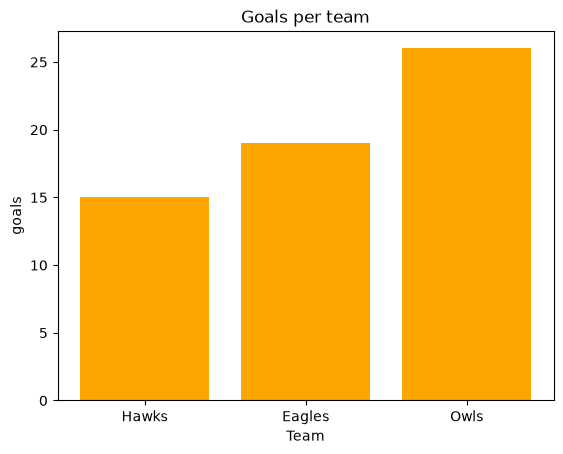

In [8]:
teams = ["Hawks", "Eagles", "Owls"]
goals = [15, 19, 26]

plt.bar(teams, goals, color="orange")
plt.title("Goals per team")
plt.xlabel("Team")
plt.ylabel("goals")
plt.show()

✏️ **Try it:** add a fourth team, change the numbers, or add `color="orange"` inside `plt.bar(...)`.

---
## Step 3: Choosing the right chart

| Chart | Code | Use it to... | Netball example |
| --- | --- | --- | --- |
| **Bar** | `plt.bar()` | Compare groups | Goals per team |
| **Horizontal bar** | `plt.barh()` | Compare groups with long names | Top 10 goal scorers |
| **Scatter** | `plt.scatter()` | See if two numbers are related | Attempts vs goals |
| **Histogram** | `plt.hist()` | See how values are spread out | Minutes played |
| **Pie** | `plt.pie()` | Show parts of a whole | Players per position |
| **Line** | `plt.plot()` | Show change over time | Goals each round |

### Chart 1: Bar chart. Which team scored the most goals?

`groupby` adds up the goals for each team. `sort_values` puts them in order.

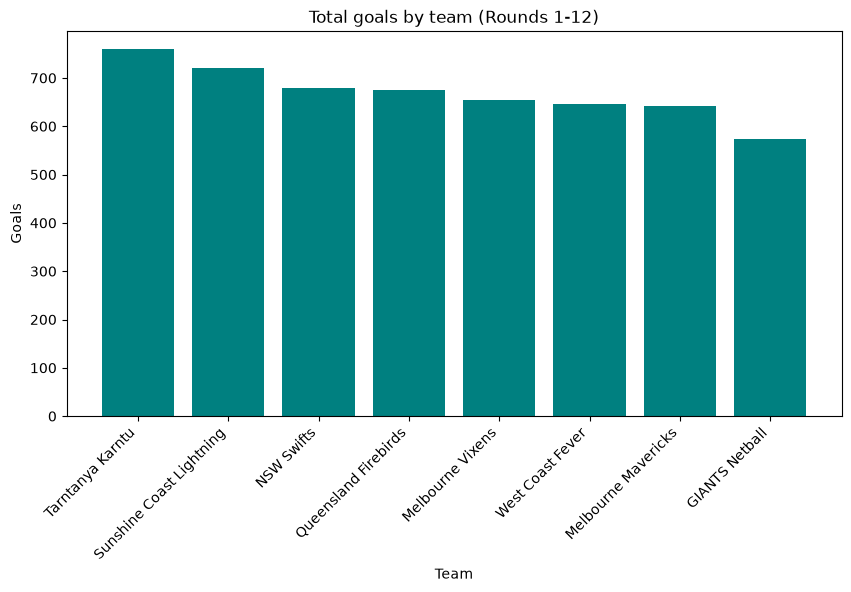

In [ ]:
team_goals = df.groupby("team")["goals"].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(team_goals.index, team_goals.values, color="teal")
plt.title("Total goals by team (Rounds 1-12)")
plt.xlabel("Team")
plt.ylabel("Goals")
plt.xticks(rotation=45, ha="right")
plt.show()

**New tricks:**
- `plt.figure(figsize=(10, 5))` makes the chart bigger (width, height)
- `plt.xticks(rotation=45)` tilts the labels so they don't overlap

### Chart 2: Horizontal bar. Who are the top 10 goal scorers?

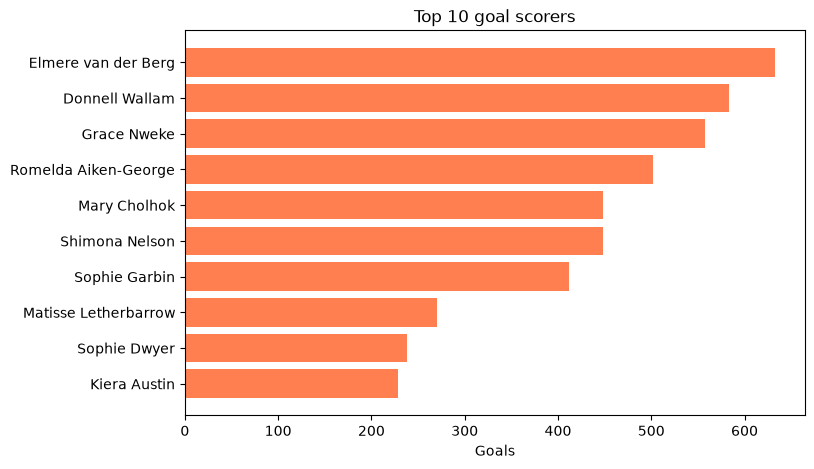

In [10]:
top10 = df.sort_values("goals", ascending=False).head(10)
names = top10["first_name"] + " " + top10["surname"]

plt.figure(figsize=(8, 5))
plt.barh(names, top10["goals"], color="coral")
plt.gca().invert_yaxis()   # puts the top scorer at the top
plt.title("Top 10 goal scorers")
plt.xlabel("Goals")
plt.show()

### Chart 3: Scatter plot. Do more attempts mean more goals?

Each dot is **one player**. We only use players who took at least one shot.

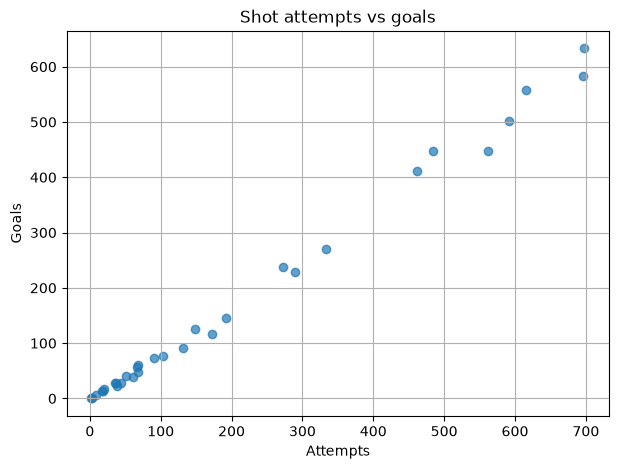

In [11]:
shooters = df[df["attempts"] > 0]

plt.figure(figsize=(7, 5))
plt.scatter(shooters["attempts"], shooters["goals"], alpha=0.7)
plt.title("Shot attempts vs goals")
plt.xlabel("Attempts")
plt.ylabel("Goals")
plt.grid(True)
plt.show()

**New tricks:** `alpha=0.7` makes the dots see-through, and `plt.grid(True)` adds grid lines.

**Think:** the dots make an almost straight line. What does that tell you?

### Chart 4: Scatter with colours. Can you see the positions?

We draw each position in its own colour and add a **legend**, a key that says what each colour means.

In [ ]:
plt.figure(figsize=(8, 6))
for pos in ["GS", "GA", "WA", "C", "WD", "GD", "GK"]:
    players = df[df["position"] == pos]
    plt.scatter(players["feeds"], players["gains"], label=pos, s=60)

plt.title("Attack (feeds) vs defence (gains) by position")
plt.xlabel("Feeds (attacking passes)")
plt.ylabel("Gains (ball won back)")
plt.legend(title="Position")
plt.show()

**Think:** attackers (WA, C) should sit bottom-right and defenders (GD, GK) top-left. Is that what you see?

### Chart 5: Histogram. How many minutes do players get?

A histogram groups numbers into **bins** (ranges) and counts how many players fall in each one.

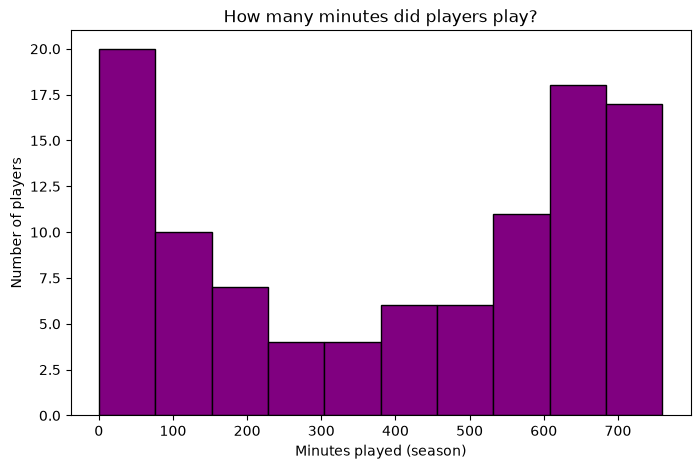

In [22]:
plt.figure(figsize=(8, 5))
plt.hist(df["minutes"], bins=10, color="purple", edgecolor="black")
plt.title("How many minutes did players play?")
plt.xlabel("Minutes played (season)")
plt.ylabel("Number of players")
plt.show()

✏️ **Try it:** change `bins=15` to `bins=5` or `bins=30`. How does the chart change?

### Chart 6: Pie chart. How many players play each position?

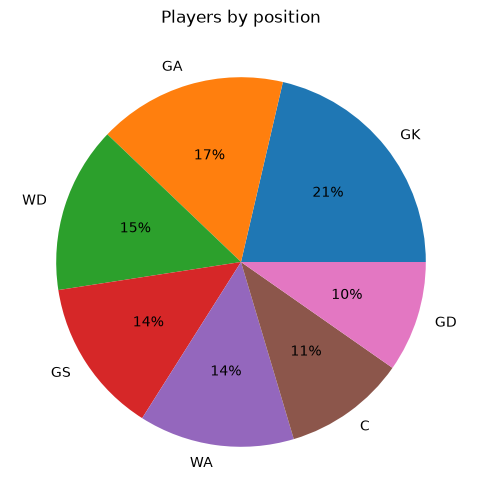

In [23]:
position_counts = df["position"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(position_counts.values, labels=position_counts.index, autopct="%1.0f%%")
plt.title("Players by position")
plt.show()

`autopct="%1.0f%%"` shows the percentage on each slice.

> **Tip:** pie charts are hard to read with lots of slices. A bar chart is often better!

### Bonus: Line chart and saving your chart

Our dataset has no rounds, so here are made-up goals for one team across 6 rounds. `plt.savefig` saves the chart as an image you can use in a presentation.

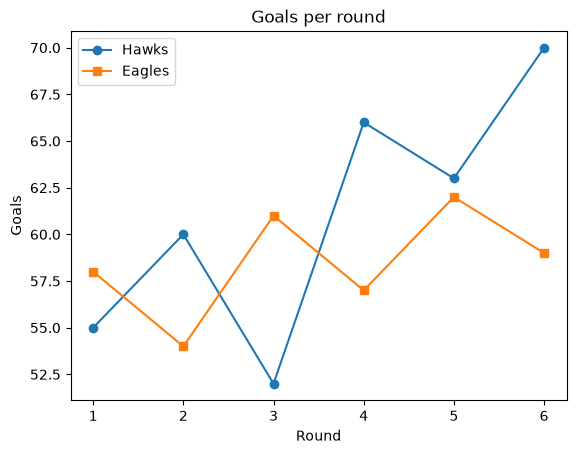

In [24]:
rounds = [1, 2, 3, 4, 5, 6]
hawks = [55, 60, 52, 66, 63, 70]
eagles = [58, 54, 61, 57, 62, 59]

plt.plot(rounds, hawks, marker="o", label="Hawks")
plt.plot(rounds, eagles, marker="s", label="Eagles")
plt.title("Goals per round")
plt.xlabel("Round")
plt.ylabel("Goals")
plt.legend()
plt.savefig("my_line_chart.png")
plt.show()

---
## Step 4: Make every chart a good chart

| ✅ Checklist | Why |
| --- | --- |
| Clear **title** | The reader knows what the chart is about |
| **Axis labels** (with units) | The reader knows what the numbers mean |
| **Legend** if there are colours | The reader knows what each colour means |
| Labels **don't overlap** | Use `figsize` or `rotation` |
| The **right chart type** | See the table in Step 3 |
| A **sentence explaining it** | Say what pattern you found |

### Common errors

| Error message | What it usually means |
| --- | --- |
| `KeyError: 'Goals'` | Wrong column name. Names are lowercase: `goals` |
| `NameError: name 'df' is not defined` | Run the Step 1 cell first |
| `NameError: name 'plt' is not defined` | Run the import cell first |
| Nothing appears | You forgot `plt.show()` |

---
## Step 5: Changing your charts with AI (NSW EduChat)

EduChat is a **tutor**. It won't write the code for you, but it **will guide you step by step** to change code you already have. That's great for you, because you'll understand every line and can explain it to the judges.

**The method:** take a chart that already works (from this notebook), paste it into EduChat, say what you want to change, and let it guide you.

### 1. Start every new EduChat chat with this message

```
I'm a high school student at a netball data hack, new to Python. My pandas DataFrame df is loaded from SSN_2026_Player_Stats_Final.csv. Columns: position, team, first_name, surname, minutes, goals, attempts, acc_pct, feeds, intercepts, deflections, gains, rebounds, penalties. Please guide me step by step to change my own code.
```

### 2. How a good prompt is built

| # | Include | Example |
| --- | --- | --- |
| 1 | **Say it's your netball code** | `This is my netball code.` |
| 2 | **What you want to change** | `I want to show total penalties by position instead of goals by team.` |
| 3 | **The exact column names** | `The columns are "position" and "penalties".` |
| 4 | **Ask for guidance** | `Can you guide me step by step?` |
| 5 | **Paste your working code** | *(copy it from the code cell)* |

### 3. Prompts to copy

Copy a prompt, then paste the code from the chart cell it mentions underneath it.

**Change the data (use Chart 1 code)**
```
This is my netball code. I want to show total penalties by position instead of goals by team. The columns are "position" and "penalties". Can you guide me step by step?
```

**Add a feature (use Chart 3 code)**
```
This is my netball scatter plot. I want to add a red line of best fit. Can you help me work out what to add, one step at a time?
```

**Change the chart type (use Chart 1 code)**
```
This is my netball bar chart. I want to change it to a box plot of penalties for each position. Can you guide me step by step?
```

**Make it look better (use any chart)**
```
This is my netball chart. I want each bar to be a different colour and the labels to be easier to read. Can you guide me?
```

**Two charts side by side (use Chart 1 code)**
```
This is my netball bar chart. I want to show goals by team and gains by team side by side using subplots. Can you guide me step by step?
```

### 4. The conversation loop

EduChat will ask you questions. **That's how it works.** Each answer gets you one step closer.

1. **Paste** your code and say what you want to change
2. **Answer** EduChat's question. Have a go, even if you're unsure!
3. **Change** your code cell and **run it**
4. **Tell EduChat** what happened, then repeat until it's done

| If EduChat asks... | You can reply... |
| --- | --- |
| *"Which columns should we use?"* | Name them exactly: *"position and penalties"* |
| *"Can you try rewriting this line?"* | Type your attempt: *"df.groupby("position")["penalties"].sum()"* |
| *"What do you think this line does?"* | Explain in your own words. A guess is fine! |
| You ran it and it worked | *"That worked! What's the next step?"* |
| You ran it and got an error | *"I changed it to ... and got this error: ... What should I check?"* |
| You've tried but you're stuck | *"I tried ... but I'm stuck. Can you give me a bigger hint?"* |
| It talks about the wrong sport or data | *"This is netball data. The columns are ..."* |

**Tips:**
- 📋 **Copy the cell first** so you keep a working version.
- 1️⃣ **Make one change at a time**, and run the code after every step.
- 🔄 **Going in circles?** Start a **new chat**, send the starter message, then your prompt.
- 🔒 **Never share personal information** in a chat.

---
## Step 6: Your turn

Copy a chart from above into a cell below, then use EduChat to help you change it to answer one of these questions:

1. Which **team** gives away the most **penalties**?
2. Which **position** gets the most **rebounds**?
3. Who are the **top 10 Super Shot** scorers (`super_shot_goals`)?
4. Is there a link between **feeds** and **goal_assists**?

**Column names:** `position, team, first_name, surname, games, quarters, minutes, goals, attempts, acc_pct, one_pt_goals, super_shot_goals, goal_assists, feeds, intercepts, deflections, gains, rebounds, penalties`

In [ ]:
# Paste a chart from above here, then change it with EduChat's help


In [ ]:
# Paste a chart from above here, then change it with EduChat's help
